# Exploring Portuguese Student Performance
## Grades, weekly study time, and school absences

**Author — Bismark Gawu**

This exploratory analysis examines 649 Portuguese-language student records from two secondary schools in Portugal. School reports and questionnaires supplied the academic, demographic, social, and school-related information. We use the Portuguese subject file, `student-por.csv`.

### Questions
1. How are final Portuguese grades distributed?
2. How do average final grades differ across weekly study-time categories?
3. How do grades differ between students with 0–10 absences and those with more than 10?

### Data source and attribution
Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Dataset documentation — https://archive.ics.uci.edu/dataset/320/student+performance

The dataset is available under CC BY 4.0 — https://creativecommons.org/licenses/by/4.0/ . Credit the dataset creator when redistributing the CSV. I completed the initial analysis and used AI assistance to review the code, organise the notebook, and refine the written explanations as part of a beginner Python learning project.


### Running this notebook
Place the original `student-por.csv` in the same folder as this notebook. Install pandas and Matplotlib in the selected Python environment, then restart the kernel and run all cells in order. All file references are relative to the working folder. Saved outputs are included for readers browsing GitHub.


## 1. Load and inspect the data
`read_csv()` reads the semicolon-separated file into a DataFrame. A row represents one student record for the Portuguese subject. We retain the complete table throughout the analysis and use `.head()` only to display previews.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Display formatting changes appearance while retaining full calculation precision.
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

portuguese_students = pd.read_csv("student-por.csv", sep=";")
display(portuguese_students.head())
print("Dataset shape:", portuguese_students.shape)
print("pandas version:", pd.__version__)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Dataset shape: (649, 33)
pandas version: 3.0.3


The file contains **649 rows and 33 columns**. The first preview displays five rows of this complete table.

| Column | Meaning |
|---|---|
| `age` | Student age in years |
| `studytime` | Ordered weekly study-time category |
| `absences` | Recorded number of school absences |
| `G3` | Final Portuguese grade, on a 0–20 scale |

| Study-time code | Weekly study time, as documented by UCI |
|---|---|
| 1 | Less than 2 hours |
| 2 | 2–5 hours |
| 3 | 5–10 hours |
| 4 | More than 10 hours |

The study-time numbers are category codes. `G3` records an individual's final grade. Group averages are calculated separately below.


In [12]:
selected_columns = ["age", "studytime", "absences", "G3"]
display(portuguese_students[selected_columns].head())


,age,studytime,absences,G3
0,18,2,4,11
1,17,2,2,11
2,15,2,6,12
3,15,3,0,14
4,16,2,0,13


The first record describes an 18-year-old in study-time category 2, with four recorded absences and a final grade of 11 out of 20. This example illustrates how to read a row.

## 2. Check data quality
`.isna()` marks missing entries and `.sum()` counts them by column. This check uses all 649 records. We also inspect data types, exact duplicate rows, and ranges in the fields used for analysis.


In [13]:
missing_counts = portuguese_students.isna().sum()
display(missing_counts.rename("Missing_values").to_frame())
display(portuguese_students[selected_columns].dtypes.rename("Data_type").to_frame())
print("Exact duplicate rows:", portuguese_students.duplicated().sum())
print("Study-time codes:", sorted(portuguese_students["studytime"].unique()))
display(portuguese_students[selected_columns].agg(["min", "max"]))


,Missing_values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


,Data_type
age,int64
studytime,int64
absences,int64
G3,int64


Exact duplicate rows: 0
Study-time codes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,age,studytime,absences,G3
min,15,1,0,0
max,22,4,32,19


All 33 columns have zero pandas-recognised missing values, and there are zero exact duplicate rows. The selected fields are integer-valued. Study-time codes cover 1–4, absences range from 0 to 32, and final grades range from 0 to 19. These checks support proceeding with the recorded values.

Zero grades are retained as observed grades. The documentation defines a 0–20 grading scale. Individual reasons for zero grades are unavailable in this analysis. Matching values across a few selected fields would also be insufficient grounds to remove a student record.

## 3. Summarise final Portuguese grades
The mean is the sum of grades divided by the number of records. The median is the middle sorted grade. The mode identifies the most frequent grade.


In [14]:
final_grades = portuguese_students["G3"]
number_of_students = len(portuguese_students)
grade_summary = pd.DataFrame({
    "Measure": ["Student records", "Mean grade", "Median grade", "Lowest grade", "Highest grade"],
    "Value": [number_of_students, final_grades.mean(), final_grades.median(),
              final_grades.min(), final_grades.max()]
})
display(grade_summary)

# Include every possible grade, including grades with no records.
grade_counts = final_grades.value_counts().reindex(range(21), fill_value=0).sort_index()
display(grade_counts.rename_axis("Final_grade").rename("Student_count").to_frame())
most_frequent_count = grade_counts.max()
modal_grades = grade_counts[grade_counts == most_frequent_count].index.tolist()
print("Most common grade(s):", modal_grades)
print("Students receiving each modal grade:", most_frequent_count)


,Measure,Value
0,Student records,649.00
1,Mean grade,11.91
2,Median grade,12.00
3,Lowest grade,0.00
4,Highest grade,19.00


,Student_count
Final_grade,
0,15
1,1
2,0
3,0
4,0
5,1
6,3
7,10
8,35


Most common grade(s): [11]
Students receiving each modal grade: 104


The mean final grade is **11.91**, and the median is **12**. Their closeness suggests similar central values under these two summaries. The most common grade is **11**, received by **104 students**, approximately **16.02%** of all records. The observed range is **0–19**, with 15 records at zero and two at 19.


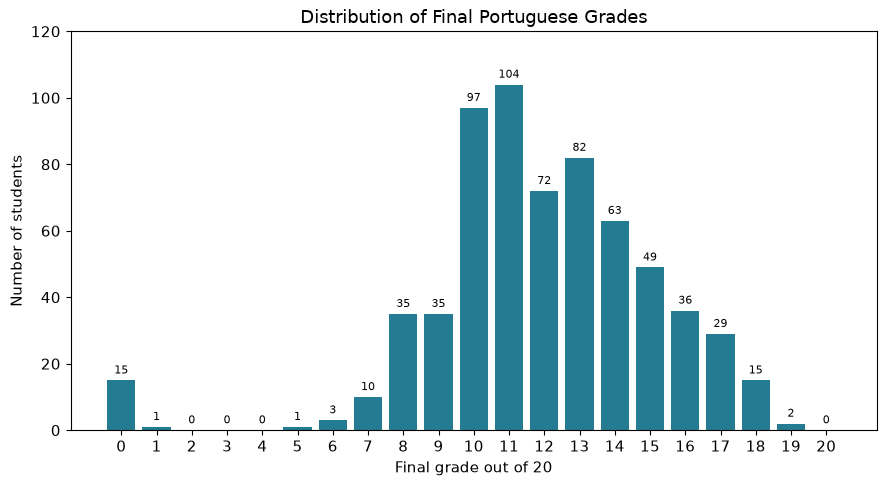

In [15]:
fig, ax = plt.subplots()
bars = ax.bar(grade_counts.index, grade_counts.values, color="#237c91")
ax.set(title="Distribution of Final Portuguese Grades",
       xlabel="Final grade out of 20", ylabel="Number of students")
ax.set_xticks(range(21))
ax.set_ylim(0, 120)
ax.bar_label(bars, padding=3, fontsize=8)
fig.tight_layout()
plt.show()


Grade 11 has the tallest bar, followed by grade 10 with 97 students. Many records fall in the 10–14 range, while the ends of the scale are less frequent. Empty positions on the chart represent grades with zero records. The 15 zero grades warrant attention when interpreting the mean, although the available fields do not establish why those grades occurred.

## 4. Compare weekly study-time groups
`groupby()` collects records sharing a study-time code. `.agg()` calculates the size and mean for each group in one table. We retain numerical results at full precision and round only their display.


In [16]:
studytime_labels = {
    1: "Under 2 hours", 2: "2–5 hours", 3: "5–10 hours", 4: "Over 10 hours"
}
studytime_summary = portuguese_students.groupby("studytime")["G3"].agg(
    Student_count="size", Average_grade="mean"
)
studytime_summary["Weekly_study_time"] = studytime_summary.index.map(studytime_labels)
studytime_summary = studytime_summary[["Weekly_study_time", "Student_count", "Average_grade"]]
display(studytime_summary)
assert studytime_summary["Student_count"].sum() == number_of_students
print("Group counts cover all", number_of_students, "records.")


,Weekly_study_time,Student_count,Average_grade
studytime,,,
1,Under 2 hours,212,10.84
2,2–5 hours,305,12.09
3,5–10 hours,97,13.23
4,Over 10 hours,35,13.06


Group counts cover all 649 records.


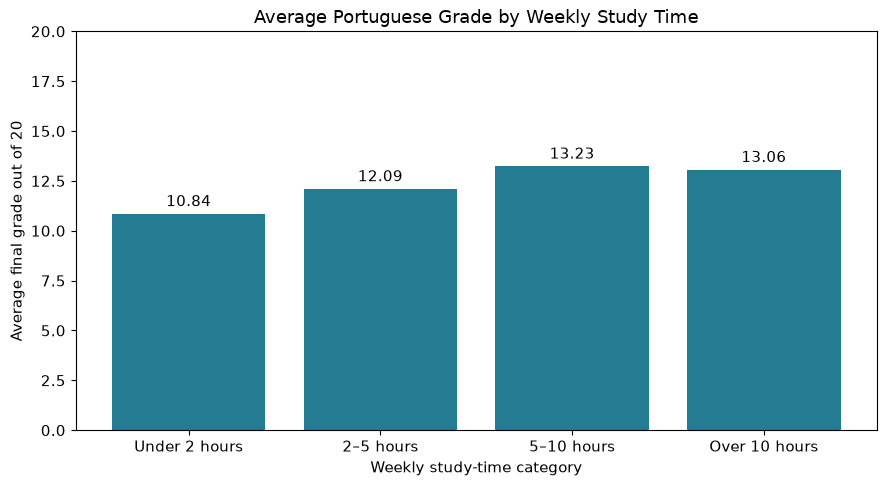

In [17]:
fig, ax = plt.subplots()
bars = ax.bar(studytime_summary["Weekly_study_time"],
              studytime_summary["Average_grade"], color="#237c91")
ax.set(title="Average Portuguese Grade by Weekly Study Time",
       xlabel="Weekly study-time category", ylabel="Average final grade out of 20", ylim=(0, 20))
ax.bar_label(bars, fmt="%.2f", padding=3)
fig.tight_layout()
plt.show()


The **2–5 hours** group is the largest, containing **305 students (46.995%, approximately 47.00%)**. It represents less than half of the dataset. Its mean grade is **12.09**.

The **5–10 hours** group has the highest mean, **13.23**, across **97 students**. The mean rises from **10.84** for under two hours to **12.09** and then **13.23**, before decreasing slightly to **13.06** in the over-ten-hours group. The final step decreases by approximately **0.17 points**.

The smallest group contains only **35 students**, compared with **212**, **305**, and **97** in the others. Consequently, the averages represent different amounts of evidence, and individual grades can have greater influence on a smaller group's mean. These are study-time group sizes, rather than classroom sizes. Differences may also reflect school, previous achievement, or other characteristics. This comparison estimates an observed association between reported study time and final grades.

## 5. Explore absences and grades
Each scatter-plot point positions one record by its absence count and final grade. Transparency helps reveal overlapping points, although several records can still occupy exactly the same location.


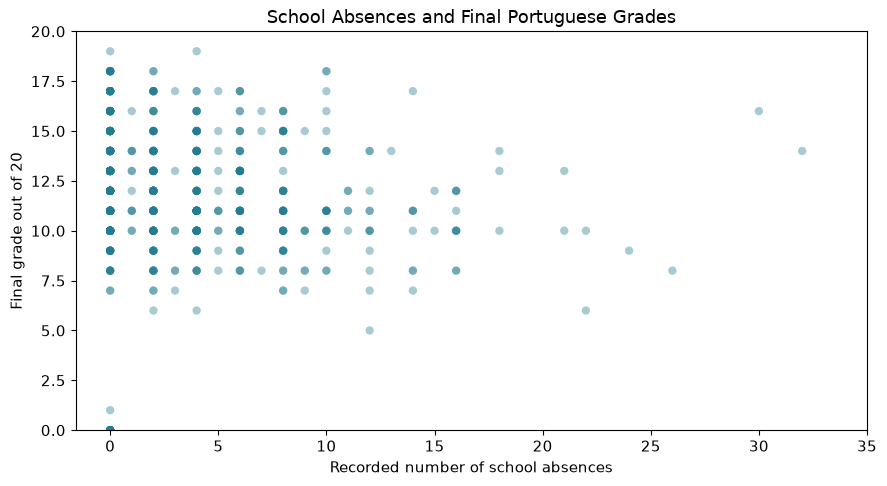

In [18]:
fig, ax = plt.subplots()
ax.scatter(portuguese_students["absences"], portuguese_students["G3"],
           alpha=0.4, color="#237c91", edgecolors="none")
ax.set(title="School Absences and Final Portuguese Grades",
       xlabel="Recorded number of school absences", ylabel="Final grade out of 20", ylim=(0, 20))
ax.set_xticks(range(0, 36, 5))
fig.tight_layout()
plt.show()


Most records cluster at relatively low absence counts. At 0–10 absences, grades span **0–19**, indicating substantial variation within this group. Fewer records have high absence counts. The density of points alone does not quantify the relationship, so we next calculate group summaries.

### Compare two absence groups
We choose **10 absences** as an exploratory cutoff. It is an analysis choice, without an established attendance-policy meaning here. The two conditions partition all records into mutually exclusive groups.


In [19]:
low_absence_students = portuguese_students[portuguese_students["absences"] <= 10]
high_absence_students = portuguese_students[portuguese_students["absences"] > 10]

low_absence_mean = low_absence_students["G3"].mean()
high_absence_mean = high_absence_students["G3"].mean()
absence_summary = pd.DataFrame({
    "Absence_group": ["0–10 absences", "Over 10 absences"],
    "Student_count": [len(low_absence_students), len(high_absence_students)],
    "Percentage": [len(low_absence_students) / number_of_students * 100,
                   len(high_absence_students) / number_of_students * 100],
    "Average_grade": [low_absence_mean, high_absence_mean]
})
display(absence_summary)
# Subtract the original means to avoid rounding before the calculation.
grade_difference = low_absence_mean - high_absence_mean
print(f"Low-absence mean minus high-absence mean: {grade_difference:.2f} grade points")
assert absence_summary["Student_count"].sum() == number_of_students
assert abs(absence_summary["Percentage"].sum() - 100) < 0.000001
print("Counts cover all records and percentages total 100%.")


,Absence_group,Student_count,Percentage,Average_grade
0,0–10 absences,600,92.45,12.01
1,Over 10 absences,49,7.55,10.65


Low-absence mean minus high-absence mean: 1.36 grade points
Counts cover all records and percentages total 100%.


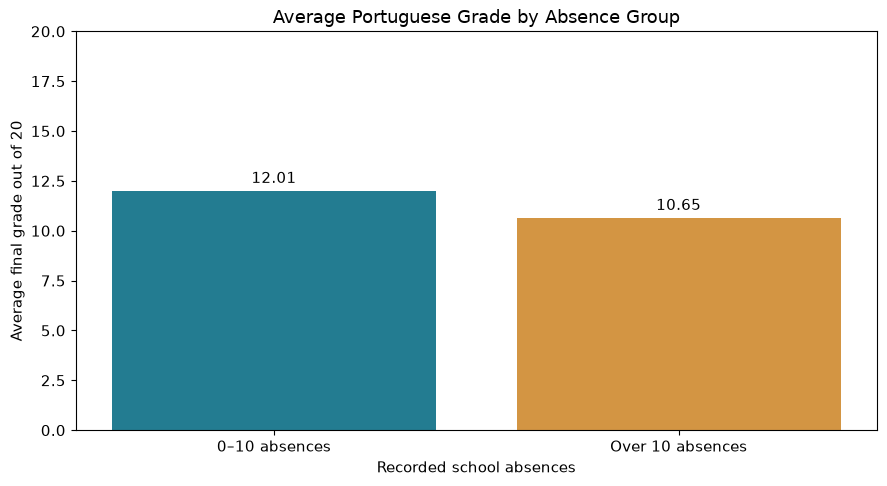

In [20]:
fig, ax = plt.subplots()
bars = ax.bar(absence_summary["Absence_group"], absence_summary["Average_grade"],
              color=["#237c91", "#d39543"])
ax.set(title="Average Portuguese Grade by Absence Group",
       xlabel="Recorded school absences", ylabel="Average final grade out of 20", ylim=(0, 20))
ax.bar_label(bars, fmt="%.2f", padding=3)
fig.tight_layout()
plt.show()


The 0–10 absences group contains **600 students (92.45%)** and averages **12.01 out of 20**. The over-ten-absences group contains **49 students (7.55%)** and averages **10.65**. Subtracting the original means gives a difference of approximately **1.36 grade points**, with the low-absence group higher.

The complete 0–20 vertical axis keeps the comparison proportional to the grading scale. The smaller high-absence group and the chosen cutoff matter when interpreting the result. Students differ in many other ways, and this grouping does not adjust for those characteristics. Statistical significance and causal effects have not been estimated in this descriptive analysis.

## 6. Conclusion
This exploratory analysis examined 649 Portuguese-language student records from two secondary schools in Portugal. Final grades averaged 11.91 out of 20, with a median of 12 and an observed range of 0–19. Grade 11 was the most frequent result, appearing in 104 records. The grade distribution therefore showed a concentration around the middle of the grading scale, alongside some very low recorded outcomes.

Study-time comparisons showed the highest average grade, 13.23, among the 97 students reporting 5–10 hours of weekly study. The 35 students reporting more than ten hours averaged 13.06. Average grades increased through the first three categories, followed by a slight decrease in the fourth.

Using ten absences as the chosen comparison cutoff, 600 students had at most ten absences and averaged 12.01. The remaining 49 averaged 10.65, producing a difference of approximately 1.36 grade points. These findings describe associations in this dataset. Unequal group sizes, reported study-time categories, and other student characteristics limit interpretation. Further investigation could compare patterns within each school and assess the influence of earlier grades.

## 7. Limitations and reproducibility
- The records come from two schools and support conclusions about this dataset. Broader generalisation requires additional evidence.
- Study time is recorded in categories collected through questionnaires. These values give approximate study-time groups.
- Group means conceal variation within each group. The exploratory summaries do not adjust for differences in prior grades or background.
- The cutoff of ten absences affects the grouping. Comparing alternative cutoffs would assess the sensitivity of the result.
- Zero grades remain in the analysis. Understanding their context could improve subsequent interpretation.
- The original CSV is kept intact. All tables and plots are generated from that file by the cells above.

### Skills demonstrated
CSV loading, DataFrame inspection, missing-value checks, descriptive statistics, filtering, grouping, percentage calculations, bar charts, scatter plots, and evidence-based interpretation.
